# Домашнее задание 1: персональные top-10 рекомендации

**Марьясов Максим Михайлович.** Amazon Reviews 2018 — **Video Games (5-core)**.

[Первоисточник UCSD](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/). Файлы загружаются с официального сервера лаборатории `mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/`; старый сервер datarepo возвращал 404/421. Рекомендуем видеоигры и игровые товары (включая аксессуары), не тексты отзывов. Выборка не относится к запрещённым MovieLens/Netflix/Last.fm. Проверены все 7 семинарных ноутбуков ветки [girafe-ai/recsys 26f](https://github.com/girafe-ai/recsys/tree/0e0b5fec7f55d08893f48254bb4380d653666ec5/seminars): используются MovieLens 100K/1M, Last.fm, Reddit, UCI Online Retail II, VK-LSVD и T-ECD Retail. Amazon Reviews Video Games среди используемых датасетов не найден; запрет на датасеты этих семинаров не затрагивает выбранный набор.

В работе пять самостоятельных реализаций из `models/`: ItemKNN, Explicit ALS, EASE, FM и Custom Target ALS. NumPy/SciPy используются для линейной алгебры, PyTorch — для autograd/оптимизатора FM. Готовые рекомендательные модели не используются.

## Воспроизведение

Python 3.12, команды из корня существующего checkout (новый worktree не нужен):

```bash
python -m venv .venv
.venv/bin/python -m pip install -r requirements.txt
OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=2 .venv/bin/python -m unittest discover -s tests -v
.venv/bin/jupyter lab experiments.ipynb
```

Затем выполнить ноутбук **сверху вниз**. Первая загрузка требует HTTPS доступа к UCSD и около 208 МБ для gzip; данные и результаты подготовки сохраняются только в игнорируемом `data/`. Сырые данные не публикуются. CPU-эксперимент использует 1 BLAS thread / 2 PyTorch threads, seed=42; веса не нужны для повторения. Запуск без UI:

```bash
OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=2 .venv/bin/jupyter nbconvert --to notebook --execute experiments.ipynb --output experiments.executed.ipynb --output-dir data/processed --ExecutePreprocessor.timeout=1800
```

CLI-альтернатива: `python -m utils.data --download`, затем `OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=2 python -m utils.experiment`. `results/` содержит только небольшие таблицы, настройки, контрольные суммы и примеры индексов рекомендаций. Повторный запуск пересчитывает результаты; скрытого кеша обучения нет. SHA256 файлов/версии библиотек записываются для аудита. Время обучения зависит от машины.

In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '2'
import random, json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
from utils.data import download, records, eda, save_prepared
root = Path('data')
download(root / 'raw')
display(json.loads((root / 'raw/manifest.json').read_text()))

mkdir -p failed for path /home/agent/.config/matplotlib: [Errno 30] Read-only file system: '/home/agent/.config/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-zwlib69u because there was an issue with the default path (/home/agent/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Fontconfig error: No writable cache directories


{'Video_Games_5.json.gz': {'url': 'https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Video_Games_5.json.gz',
  'sha256': 'a0bd63e90ad3bd577778678672bb2e7e88b8c085683c86aca2f18c1ab543cb84'},
 'meta_Video_Games.json.gz': {'url': 'https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/metaFiles2/meta_Video_Games.json.gz',
  'sha256': '4069e17c7efa33e7574c2e77f1fe0b0c6f2a42a7ac29c4422696d788d8a8e0a6'}}

## 1. Данные и поля

Один отзыв — наблюдаемое взаимодействие. `reviewerID`: пользователь; `asin`: товар; `overall`: оценка 1–5; `unixReviewTime`: время Unix, переводим в UTC. `title`, `brand`, `category` описывают товар. `reviewText`, `summary`, `vote`, `verified` — атрибуты отзыва, их не используем для предсказания будущего события. Строки метаданных охватывают полную категорию, поэтому их больше, чем товаров в 5-core.

**Общий критерий релевантности:** отложенный `rating >= 4`. ALS/FM обучаются на всех наблюдаемых рейтингах; ItemKNN/EASE — на положительных взаимодействиях. Их разные таргеты не меняют критерий оценки.

In [2]:
reviews = pd.DataFrame(records(root / 'raw/Video_Games_5.json.gz'))
metadata = pd.DataFrame(records(root / 'raw/meta_Video_Games.json.gz'))
audit = eda(reviews, metadata)
display({k: audit[k] for k in ['reviews_shape', 'metadata_shape', 'users', 'items', 'unique_pairs',
    'exact_duplicate_reviews', 'duplicate_user_item', 'duplicate_metadata_asin',
    'time_min', 'time_max', 'invalid_timestamps', 'metadata_coverage', 'sparsity_unique_pairs']})
display(pd.Series(audit['missing_reviews'], name='missing_reviews').to_frame())
display(pd.DataFrame({'missing': audit['missing_metadata'], 'empty_string_or_list': audit['empty_metadata']}))

{'reviews_shape': [497577, 12],
 'metadata_shape': [84819, 19],
 'users': 55223,
 'items': 17408,
 'unique_pairs': 473427,
 'exact_duplicate_reviews': 23287,
 'duplicate_user_item': 24150,
 'duplicate_metadata_asin': 12908,
 'time_min': '1999-10-14 00:00:00+00:00',
 'time_max': '2018-10-02 00:00:00+00:00',
 'invalid_timestamps': 0,
 'metadata_coverage': 0.9974637091344656,
 'sparsity_unique_pairs': 0.9995075250458435}

,missing_reviews
overall,0
verified,0
reviewTime,0
reviewerID,0
asin,0
reviewerName,76
reviewText,158
summary,109
unixReviewTime,0
vote,389784


,missing,empty_string_or_list
category,0,2425
tech1,0,81972
description,0,10159
fit,0,84819
title,0,11
also_buy,0,49424
tech2,0,84585
brand,0,4027
feature,0,22871
rank,0,4500


## 2. EDA

Активность и популярность считаем по уникальным user/item: дубликаты не должны увеличивать плотность. Разреженность равна $1-|\Omega|/(|U||I|)$. EDA всего источника используется для описания данных, а не для обучения признаков или выбора гиперпараметров.

,user_activity,item_popularity
count,55223.000000,17408.000000
mean,8.573004,27.195944
std,10.095808,47.372128
min,1.000000,1.000000
50%,6.000000,12.000000
90%,14.000000,58.000000
99%,41.000000,251.000000
max,779.000000,782.000000


,brand_count
,4027
by\n \n Electronic Arts,2612
by\n \n Activision,2292
by\n \n Nintendo,1931
by\n \n Sega,1569
by\n \n Ubisoft,1566
Nintendo,1496
by\n \n Sony,1379
by\n \n Atari,1063
by\n \n Microsoft,1050


[['Video Games', 'PC', 'Games'],
 ['Video Games', 'Xbox 360', 'Games', '</span></span></span>'],
 ['Video Games', 'Retro Gaming & Microconsoles', 'Super Nintendo', 'Games'],
 ['Video Games',
  'Xbox 360',
  'Accessories',
  'Controllers',
  'Joysticks',
  '</span></span></span>',
  'Original PCB used from Xbox 360 Control Pad (to ensure 100% compatibility)',
  'FULL SIZE MAS STICK',
  'Special Design for Xbox 360 (Street Fighter Button Layout)',
  'Uses USB port of your Xbox 360 (not wireless),Works with PC games as well',
  'Perfect 360 Optical Stick by HAPP (used in most U.S. Arcades)'],
 ['Video Games',
  'PC',
  'Games',
  '</span></span></span>',
  'Grades 2-12',
  'Spelling Program',
  'Teaches Spelling Rules',
  'Treats Sight Words',
  'Records Results']]

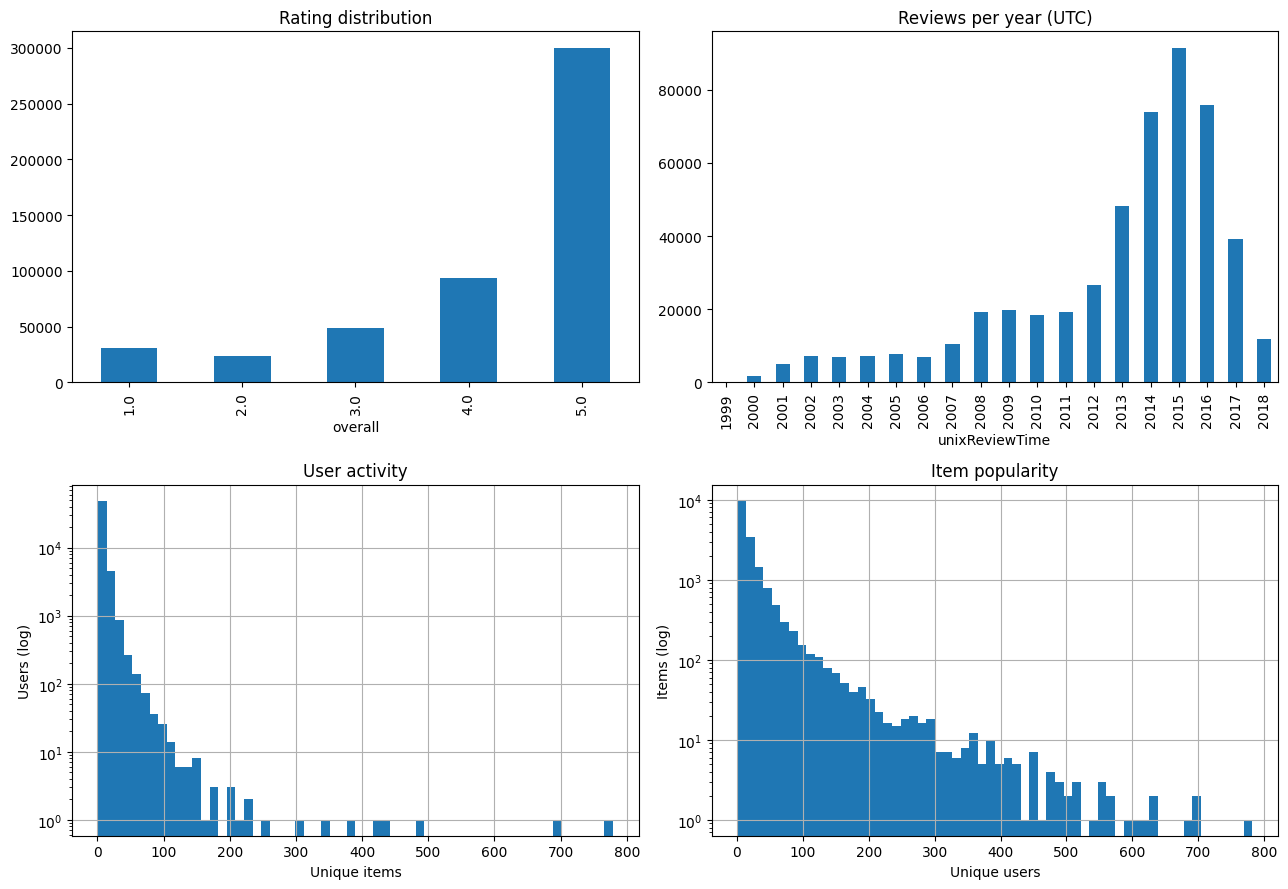

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
reviews.overall.value_counts().sort_index().plot.bar(ax=axes[0,0], title='Rating distribution')
pd.to_datetime(reviews.unixReviewTime, unit='s', utc=True).dt.year.value_counts().sort_index().plot.bar(ax=axes[0,1], title='Reviews per year (UTC)')
pairs = reviews[['reviewerID', 'asin']].drop_duplicates()
pairs.groupby('reviewerID').size().hist(bins=60, log=True, ax=axes[1,0])
axes[1,0].set(title='User activity', xlabel='Unique items', ylabel='Users (log)')
pairs.groupby('asin').size().hist(bins=60, log=True, ax=axes[1,1])
axes[1,1].set(title='Item popularity', xlabel='Unique users', ylabel='Items (log)')
plt.tight_layout()
display(pd.DataFrame({'user_activity':audit['user_activity_unique_items'], 'item_popularity':audit['item_popularity_unique_users']}))
display(pd.Series(audit['brands_top'],name='brand_count').to_frame())
display(audit['category_examples'])

### Очистка, подвыборка и утечки

* Убираем отсутствие ID/оценки/времени, оценки вне [1,5], неположительное время. Стабильная сортировка: timestamp, user, ASIN, rating. У повторов user/item оставляем самое раннее событие; при равном timestamp — меньший rating. Будущий отзыв не заменяет прошлую оценку.
* После очистки задаём глобальные границы 80%/90% временных меток с округлением к наблюдаемому времени вниз; одинаковый timestamp не делится. Это ретроспективный протокол по времени, а не онлайн-выбор дат: для строгого backtest календарные границы следовало бы зафиксировать заранее. Оценки и популярность holdout не определяют каталог.
* Только по train выбираем top-5000 товаров по числу взаимодействий, при равенстве ASIN по возрастанию. Каталог около 2000 был ориентиром: 5000 оставляет больше разнообразия и посилен текущей машине. Одна float64 матрица EASE занимает 200 МБ, при решении требуется несколько таких матриц.
* Общий бюджет 2 млн заранее распределён как 1,6 млн train / 200 тыс. validation / 200 тыс. test (сохраняются последние события). На фактических данных этот лимит не сработал. Обязательны >=100 тыс. train-взаимодействий, >=1000 пользователей и товаров; при нарушении код завершается ошибкой, пороги автоматически не ослабляются.
* Индексы определяются только train. Holdout ограничивается известными пользователями и товарами. Это warm-start задача; исключённые строки явно считаются. Внешний 5-core сформирован поставщиком по всему периоду и несёт selection bias; после разбиения train не обязан оставаться 5-core.
* Запрещены будущие агрегаты рейтингов, отзывов, sales rank, also_buy/also_view, цена текущего снимка. Метаданные дублирующихся ASIN разрешаются выбором первой записи. Загружаемый снимок недатирован: доказать историческую доступность бренда/платформы нельзя. Для FM принимаем предположение, что производитель и платформа — постоянные свойства товара, известные при его появлении. Это **ограничение**, а не доказанная гарантия отсутствия временной утечки; для строгого исследования нужен исторический снимок. Динамические поля исключены.


In [4]:
splits, preparation = save_prepared(reviews, metadata, root)
train, validation, test_for_data_audit = splits
summary = []
for name, part in zip(['train','validation','test'], splits):
    summary.append({'split':name,'interactions':len(part),'users':part.reviewerID.nunique(),
                    'items':part.asin.nunique(),
                    'start_utc':str(pd.to_datetime(part.unixReviewTime.min(),unit='s',utc=True).date()),
                    'end_utc':str(pd.to_datetime(part.unixReviewTime.max(),unit='s',utc=True).date())})
display(pd.DataFrame(summary))
print('Total:',sum(len(p) for p in splits))
print('Excluded:',preparation['excluded_rows'])
print('Train sparsity:',1-len(train)/(train.reviewerID.nunique()*train.asin.nunique()))
assert 100000 <= sum(len(p) for p in splits) <= 2000000
assert train.reviewerID.nunique() >= 1000 and train.asin.nunique() >= 1000
# Test data above is used only for preparation/audit, never validation selection.
del splits, test_for_data_audit

{
  "cutoffs_unix": [
    1462406400,
    1484438400
  ],
  "raw_split_rows": [
    378850,
    47385,
    47192
  ],
  "prepared_split_rows": [
    283093,
    13743,
    10763
  ],
  "excluded_rows": [
    95757,
    33642,
    36429
  ],
  "train_users": 49162,
  "train_items": 5000,
  "ease_float64_matrix_bytes": 200000000,
  "constraint_scope": "at least 100k in train by default; at most 2M across all splits"
}


,split,interactions,users,items,start_utc,end_utc
0,train,283093,49162,5000,1999-10-14,2016-05-05
1,validation,13743,6865,3182,2016-05-06,2017-01-15
2,test,10763,5587,2932,2017-01-16,2018-09-15


Total: 307599
Excluded: [95757, 33642, 36429]


Train sparsity: 0.9988483259428014


## 3. Единый протокол оценки

До подбора выбираем **NDCG@10** основной метрикой: важен порядок релевантных товаров на первых позициях. **Recall@10** — доля релевантных товаров, попавших в десятку. Это макросредние по пользователям с >=1 положительным отложенным событием, не микросредние по событиям.

$$Recall@10(u)=|R_u\cap L_u^{10}|/|R_u|,$$
$$NDCG@10(u)=\frac{\sum_{j=1}^{10}\mathbf 1[L_{uj}\in R_u]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}.$$

Когорты validation и test отдельно фиксируются из отложенных положительных событий и одинаковы для всех моделей на соответствующем split. Хеши когорт записываются. При validation исключаем все train-товары пользователя, включая низкие рейтинги; при test — train+validation. Кандидаты — все допустимые товары **единого train-каталога**, без негативного семплирования. Новые пользователи/товары исключены на стадии подготовки. Равные score разрешаются по item_idx по возрастанию; индексы соответствуют лексикографическому ASIN. Если доступно меньше 10 кандидатов, evaluator выдаёт ошибку.

**Переобучения на train+validation нет ни для одной модели.** Validation используется только для выбора параметров. Все финальные модели сохраняют обучение только на train, но известные к test validation-товары маскируются. Общий критерий релевантности rating>=4 не меняется. Test в runner читается только после записи выбранных настроек; метаданные и словари — только train-каталог.


## 4. Самостоятельные реализации

### ItemKNN (`models/item_knn.py`)
$X_{ui}=1[r_{ui}\ge4]$ на train, $c_{ij}=(X^TX)_{ij}$.
$$s_{ij}=\frac{c_{ij}}{\sqrt{c_{ii}c_{jj}}}\frac{c_{ij}}{c_{ij}+\beta},\quad s_{ii}=0.$$
При $\beta=0$ множитель shrinkage равен 1. Нулевые нормы дают нулевое сходство. Для каждого исходного товара оставляем k ближайших соседей; $\hat y_u=X_u S_k$. Матрица разреженная, известные объекты маскируются общим evaluator.

### Explicit ALS (`models/als.py`)
$$\min_{P,Q}\sum_{(u,i)\in\Omega}(r_{ui}-p_u^Tq_i)^2+\lambda(\|P\|_F^2+\|Q\|_F^2).$$
$$p_u=(Q_{I_u}^TQ_{I_u}+\lambda I)^{-1}Q_{I_u}^Tr_u.$$
Попеременно решаем системы для пользователей и товаров через `np.linalg.solve`. Неизвестные рейтинги не равны нулям и в objective не входят. Регуляризация не умножается на число взаимодействий. Score — скалярное произведение без bias и clipping.

### EASE (`models/ease.py`)
Для бинарного положительного X решаем
$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\quad \operatorname{diag}(B)=0.$$
$$P=(X^TX+\lambda I)^{-1},\quad B_{ij}=-P_{ij}/P_{jj},\quad B_{jj}=0.$$
Используем Cholesky и решение системы, а не готовую модель. Score $X_uB$.

### FM (`models/fm.py`, `utils/features.py`)
$$\hat r(x)=b+\sum_a w_a x_a+\frac12\sum_f\left[(\sum_a v_{af}x_a)^2-\sum_a v_{af}^2x_a^2\right].$$
Активны четыре категориальных поля: user ID, item ID, **бренд и платформа** (второй уровень category). Для них отдельные пространства ID. HTML/префикс `by` и пробелы очищаются; отсутствующим значениям соответствует UNK. Словари fit только на train-каталоге, чужие строки metadata не влияют на них. Не используем хвосты category, где встречается рекламный текст. Бренд/платформа помогают объединять похожие товары, в отличие от одних ID. Проблема недатированного снимка описана выше.

Обучение: MSE наблюдаемых рейтингов плюс $\lambda |\Omega|^{-1}\sum_{(u,i)}\sum_{a\in A(x_{ui})}(w_a^2+\|v_a\|^2)$; bias не регуляризуется. Собственная формула FM и training loop, autograd/Adam разрешены. Веса инициализированы нулями, факторы $N(0,0.03^2)$, bias средним train-rating. Полный scorer точно раскладывает FM на пользовательскую часть и заранее вычисленную сумму item/meta-факторов; он проверен на равенство forward. Дополнительно обучаем FM только с user/item ID при выбранных настройках полной FM — условная абляция, не отдельно оптимизированная лучшая ID-only модель.

### Custom Target ALS (`models/custom_als.py`)
$$y_{ui}=\frac{r_{ui}-3}{2}\left[\alpha+(1-\alpha)\exp(-age_{ui}/\tau)\right],$$
где $age_{ui}=(t_{\max,train}-t_{ui})/86400$, $\tau$ в днях. Нейтральный рейтинг 3 становится нулём, 1–2 отрицательными, 4–5 положительными; старые сильные предпочтения приближаются к нейтральному уровню, но сохраняют нижнюю долю $\alpha$. Используется **та же невзвешенная ALS-задача**, в которой r заменяется на y. Нулевые target остаются наблюдаемыми, confidence не изменяется. При $\alpha=1$ затухания нет — полезный контроль центрирования/масштабирования.

Ограничения: календарная давность не обязательно отражает личное изменение вкуса, а target меняет и масштаб относительно регуляризации. Не заявляем, что эффект вызван только временем. Rank/regularization/iterations берём у выбранного базового ALS, а alpha/tau выбираем на validation. Одинаковые тестовые рейтинги>=4 и общий evaluator позволяют сравнить модели, но это небольшой поиск, не доказательство оптимальности.


## 5. Подбор на validation, затем финальный test

Небольшой поиск соответствует доступному CPU-бюджету; число итераций фиксировано заранее (ALS — 8, FM — 8 эпох). Для всех конфигураций seed=42. Не останавливаем обучение по test. Поиск: ItemKNN 4, ALS 4, EASE 3, FM 4, Custom ALS 3 конфигурации. Custom использует выбранный solver базового ALS. При равной validation NDCG выбирается первая конфигурация в заранее объявленном порядке. Popularity — дополнительный неперсональный контроль по числу положительных train-взаимодействий, не одна из пяти обязательных моделей.

Следующая ячейка показывает весь поиск **до запуска обучения**. Потом runner сохраняет каждую validation-строку, фиксирует настройки и лишь после этого читает test. Абляция FM не используется для смены лучшей полной FM.

Перед чтением таблиц вызывается `verify_results()`: статус запуска должен быть `completed`, а контрольные суммы таблиц — совпадать с `results/status.json`. При прерванном запуске статус остаётся `running`; прежние таблицы не считаются текущим результатом.

In [5]:
from utils.experiment import run, GRIDS, CUSTOM_GRID
from models.item_knn import ItemKNN
from models.als import ExplicitALS
from models.ease import EASE
from models.fm import FM
from models.custom_als import CustomALS
display(GRIDS)
display(CUSTOM_GRID)

{'ItemKNN': {'neighbors': [40, 100], 'shrinkage': [0, 20]},
 'ExplicitALS': {'rank': [8, 16],
  'regularization': [1.0, 10.0],
  'iterations': [8],
  'seed': [42]},
 'EASE': {'regularization': [10.0, 100.0, 1000.0]},
 'FM': {'rank': [8, 16],
  'regularization': [0.0001, 0.001],
  'learning_rate': [0.01],
  'epochs': [8],
  'seed': [42]}}

[{'alpha': 0.25, 'tau_days': 180},
 {'alpha': 0.5, 'tau_days': 365},
 {'alpha': 1.0, 'tau_days': 365}]

In [6]:
final_results = run(data_dir=root, output_dir='results')

VALIDATION ItemKNN {'neighbors': 40, 'shrinkage': 0} {'NDCG@10': 0.0268913867680235, 'Recall@10': 0.04270426669609645, 'users': 5721} fit seconds 0.76


VALIDATION ItemKNN {'neighbors': 40, 'shrinkage': 20} {'NDCG@10': 0.03051784484812342, 'Recall@10': 0.050354832205864904, 'users': 5721} fit seconds 0.86


VALIDATION ItemKNN {'neighbors': 100, 'shrinkage': 0} {'NDCG@10': 0.027491125152907817, 'Recall@10': 0.04403388987209059, 'users': 5721} fit seconds 0.76


VALIDATION ItemKNN {'neighbors': 100, 'shrinkage': 20} {'NDCG@10': 0.030626209383236472, 'Recall@10': 0.05034797788595343, 'users': 5721} fit seconds 0.91


VALIDATION ExplicitALS {'rank': 8, 'regularization': 1.0, 'iterations': 8, 'seed': 42} {'NDCG@10': 0.0033192955462875606, 'Recall@10': 0.005957395221904585, 'users': 5721} fit seconds 5.47


...

TEST FM {'NDCG@10': 0.0034182242986252115, 'Recall@10': 0.006608897408501456, 'users': 4546}


TEST CustomALS {'NDCG@10': 0.019770430185742684, 'Recall@10': 0.03490561649259494, 'users': 4546}


TEST FM_ID_only_ablation {'NDCG@10': 0.0019682128062463227, 'Recall@10': 0.003254038086858148, 'users': 4546}


TEST Popularity_baseline {'NDCG@10': 0.009892236731740488, 'Recall@10': 0.01896796222234059, 'users': 4546}


Experiment complete; results: results


,model,params,NDCG@10,Recall@10,fit_seconds
0,ItemKNN,"{""neighbors"": 40, ""shrinkage"": 0}",0.026891,0.042704,0.760282
1,ItemKNN,"{""neighbors"": 40, ""shrinkage"": 20}",0.030518,0.050355,0.857531
2,ItemKNN,"{""neighbors"": 100, ""shrinkage"": 0}",0.027491,0.044034,0.761123
3,ItemKNN,"{""neighbors"": 100, ""shrinkage"": 20}",0.030626,0.050348,0.906576
4,ExplicitALS,"{""iterations"": 8, ""rank"": 8, ""regularization"":...",0.003319,0.005957,5.469170
5,ExplicitALS,"{""iterations"": 8, ""rank"": 8, ""regularization"":...",0.013466,0.024346,5.379325
6,ExplicitALS,"{""iterations"": 8, ""rank"": 16, ""regularization""...",0.001330,0.002612,6.795971
7,ExplicitALS,"{""iterations"": 8, ""rank"": 16, ""regularization""...",0.014177,0.025743,6.294047
8,EASE,"{""regularization"": 10.0}",0.030433,0.049385,8.070867
9,EASE,"{""regularization"": 100.0}",0.032352,0.053445,7.225245


{'ItemKNN': {'neighbors': 100, 'shrinkage': 20},
 'ExplicitALS': {'rank': 16,
  'regularization': 10.0,
  'iterations': 8,
  'seed': 42},
 'EASE': {'regularization': 100.0},
 'FM': {'rank': 16,
  'regularization': 0.0001,
  'learning_rate': 0.01,
  'epochs': 8,
  'seed': 42},
 'CustomALS': {'rank': 16,
  'regularization': 10.0,
  'iterations': 8,
  'seed': 42,
  'alpha': 0.25,
  'tau_days': 180},
 'FM_ID_only_ablation': {'rank': 16,
  'regularization': 0.0001,
  'learning_rate': 0.01,
  'epochs': 8,
  'seed': 42,
  'include_metadata': False},
 'Popularity_baseline': {}}

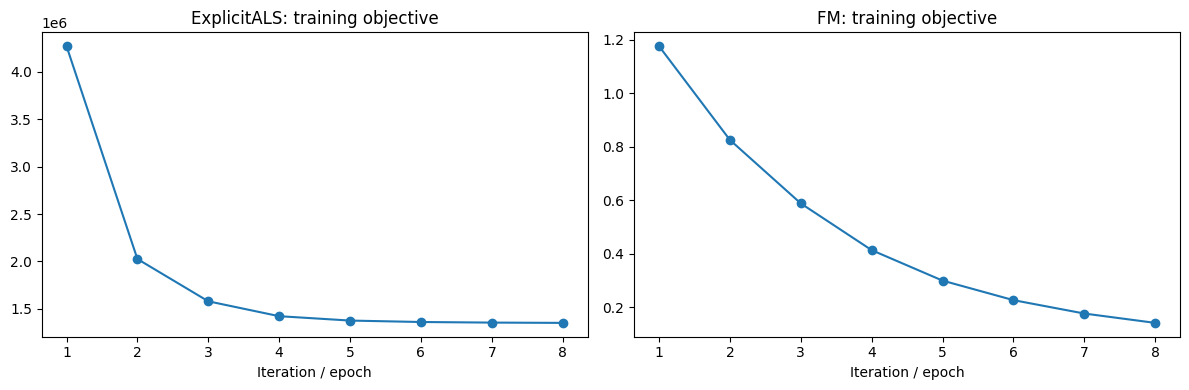

In [7]:
from utils.experiment import verify_results
_ = verify_results('results')
validation_results = pd.read_csv('results/validation.csv')
selected = json.loads(Path('results/selected.json').read_text())
display(validation_results[['model','params','NDCG@10','Recall@10','fit_seconds']])
display(selected)
# Истории оптимизации ALS — objective sum, FM — средний batch loss; шкалы различны.
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for name, ax in [('ExplicitALS',axes[0]),('FM',axes[1])]:
    matching = validation_results[validation_results.model.eq(name)].copy()
    best = matching.loc[matching['NDCG@10'].idxmax()]
    history = json.loads(best.loss_history)
    ax.plot(range(1,len(history)+1),history,marker='o')
    ax.set(title=f'{name}: training objective',xlabel='Iteration / epoch')
plt.tight_layout()

## 6. Итоговые метрики и параметры

Таблица ниже — финальная оценка фиксированных настроек. Небольшие абсолютные значения ожидаемы при полном каталоге и коротком отложенном списке релевантных товаров; сравнивать их с sampled-negative протоколом нельзя.

,model,NDCG@10,Recall@10,users,params
0,EASE,0.025918,0.040385,4546,"{""regularization"": 100.0}"
1,ItemKNN,0.023470,0.038804,4546,"{""neighbors"": 100, ""shrinkage"": 20}"
2,CustomALS,0.019770,0.034906,4546,"{""alpha"": 0.25, ""iterations"": 8, ""rank"": 16, ""..."
3,ExplicitALS,0.013638,0.024537,4546,"{""iterations"": 8, ""rank"": 16, ""regularization""..."
4,Popularity_baseline,0.009892,0.018968,4546,{}
5,FM,0.003418,0.006609,4546,"{""epochs"": 8, ""learning_rate"": 0.01, ""rank"": 1..."
6,FM_ID_only_ablation,0.001968,0.003254,4546,"{""epochs"": 8, ""include_metadata"": false, ""lear..."


Validation users: 5721 Test users: 4546


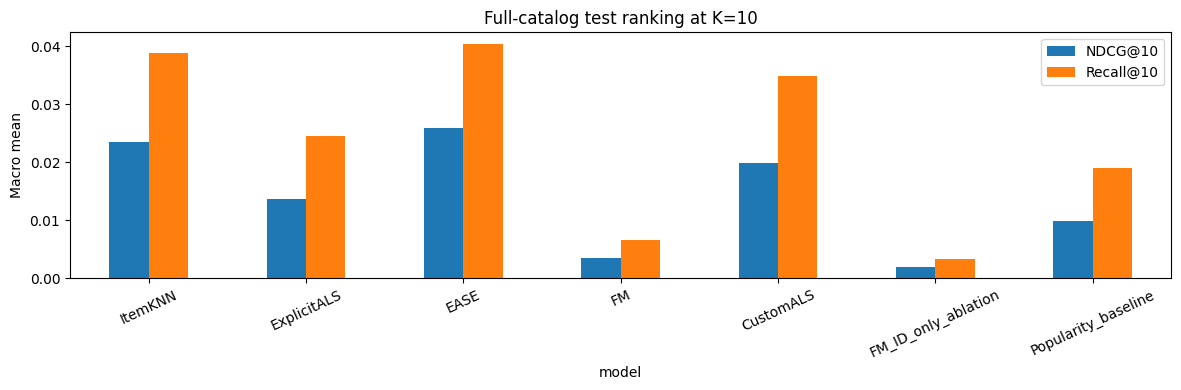

In [8]:
display(final_results.sort_values('NDCG@10',ascending=False).reset_index(drop=True))
protocol = json.loads(Path('results/protocol.json').read_text())
print('Validation users:',protocol['validation_users'],'Test users:',protocol['test_users'])
ax = final_results.set_index('model')[['NDCG@10','Recall@10']].plot.bar(figsize=(12,4), rot=25)
ax.set(title='Full-catalog test ranking at K=10',ylabel='Macro mean')
plt.tight_layout()

### Примеры персональных top-10

Одни и те же три пользователя из test-когорты, с исключением известных train+validation товаров. Это демонстрация работы, не дополнительный подбор. Индексы пользователей локальные; текст отзывов и исходные user ID не публикуются.

In [9]:
examples = json.loads(Path('results/recommendations.json').read_text())
item_asin = train[['item_idx','asin']].drop_duplicates().set_index('item_idx').asin.to_dict()
titles = metadata.drop_duplicates('asin').set_index('asin').title.to_dict()
for model_name in ['ItemKNN','ExplicitALS','EASE','FM','CustomALS']:
    user_idx = examples['user_idx'][0]
    recs = examples['top10_item_idx'][model_name][0]
    print(model_name, 'user_idx=',user_idx)
    display(pd.DataFrame({'rank':range(1,11), 'asin':[item_asin[i] for i in recs],
                          'title':[titles.get(item_asin[i],'<UNK>') for i in recs]}))

ItemKNN user_idx= 2


,rank,asin,title
0,1,B0050SX1JO,Sports Champions 2 - Playstation 3
1,2,B00D7TYIY0,Just Dance 2014 - Playstation 3
2,3,B0050SXQ12,PS3 Everybody Dance
3,4,B002I0J8KS,The Fight
4,5,B00KTNSKT6,Just Dance 2015 - PlayStation 3
5,6,B0072HYRNK,Sony PlayStation 3 Move Motion Controller (Bul...
6,7,B0017HPE6K,Sonic Unleashed - Playstation 3
7,8,B004X56PWK,Sonic Generations - PlayStation 3
8,9,B0041RWIGW,PS3 Move Quad Charger
9,10,B005T5OCAK,Deadmund's Quest Move Bundle - Playstation 3


ExplicitALS user_idx= 2


,rank,asin,title
0,1,B004FS8LYK,Tomb Raider
1,2,B0016C3260,<UNK>
2,3,B0017KIBAI,Official Nintendo White Classic Gamecube Contr...
3,4,B0053BCML6,Animal Crossing: New Leaf
4,5,B00DD0B1R0,Super Smash Bros. - Nintendo 3DS
5,6,B0050SVNZ8,AmazonBasics Carrying Case for Nintendo - New ...
6,7,B003VUO6H4,Sony Playstation 3 160GB System
7,8,B00KWFCSB2,Super Mario Maker - Nintendo Wii U
8,9,B003O6E3C8,Portal 2 - Playstation 3
9,10,B0040546HY,PlayStation 3 Dualshock 3 Wireless Controller ...


EASE user_idx= 2


,rank,asin,title
0,1,B0050SX1JO,Sports Champions 2 - Playstation 3
1,2,B0050SXQ12,PS3 Everybody Dance
2,3,B00D7TYIY0,Just Dance 2014 - Playstation 3
3,4,B004X56PWK,Sonic Generations - PlayStation 3
4,5,B002I0J8KS,The Fight
5,6,B0072HYRNK,Sony PlayStation 3 Move Motion Controller (Bul...
6,7,B00KTNSKT6,Just Dance 2015 - PlayStation 3
7,8,B00A750QIE,MLB 13 The Show - Playstation 3
8,9,B009CYJ8SA,PS3 250GB Uncharted 3: Game of the Year Bundle
9,10,B0050SXPBI,Carnival Island - Playstation 3


FM user_idx= 2


,rank,asin,title
0,1,B000G7YX4G,Marvel Ultimate Alliance - PlayStation 2
1,2,B000063SAU,Medieval: Total War - PC
2,3,B0081716P2,Pikmin 2 (Nintendo Selects) - Nintendo Wii
3,4,B0009UBR3A,The Legend of Zelda: Twilight Princess
4,5,B01307Q6ZC,Nintendo NFC Reader/Writer Accessory - Nintend...
5,6,B00Y074JOM,Zero Suit Samus amiibo - Japan Import (Super S...
6,7,B00S1LRUVW,Nintendo New 3DS Xl - Red [Discontinued]
7,8,B000E991PC,Okami - PlayStation 2
8,9,B00000IODY,Syphon Filter
9,10,B003XNU1M8,Super Mario World - Wii U [Digital Code]


CustomALS user_idx= 2


,rank,asin,title
0,1,B00YQ2KCWO,Fallout 4 - PlayStation 4
1,2,B00N4ABT1C,Yoshi amiibo (Super Smash Bros Series)
2,3,B00WTI3JPE,The Witcher 3: Wild Hunt - PlayStation 4
3,4,B00KVR4HEC,Bloodborne
4,5,B00JK00S0S,The Last of Us Remastered - PlayStation 4
5,6,B00JKM06HG,Metal Gear Solid V: The Phantom Pain - PlaySta...
6,7,B00MV7KVP4,Until Dawn - PlayStation 4
7,8,B00DC7G2W8,Mario Kart 8 - Nintendo Wii U
8,9,B00Z7V9P8K,Batman: Arkham Knight - PlayStation 4 [Digital...
9,10,B00KWFCSB2,Super Mario Maker - Nintendo Wii U


## 7. Выводы по фактическим результатам

Числа в следующей ячейке вычисляются из результатов именно этого запуска, не вписаны вручную. Для влияния метаданных используется сопоставление полной и ID-only FM при одинаковых выбранных параметрах; для кастомного сигнала — сравнение с Explicit ALS. Это описательные различия без проверки статистической значимости.

In [10]:
table = final_results.set_index('model')
required = ['ItemKNN','ExplicitALS','EASE','FM','CustomALS']
winner = table.loc[required,'NDCG@10'].idxmax()
print(f"Лучший из пяти по test NDCG@10: {winner}: {table.loc[winner,'NDCG@10']:.6f}")
print(f"Его Recall@10: {table.loc[winner,'Recall@10']:.6f}; параметры: {selected[winner]}")
for a,b,label in [('FM','FM_ID_only_ablation','Метаданные FM'),('CustomALS','ExplicitALS','Кастомный target')]:
    for metric in ['NDCG@10','Recall@10']:
        delta = table.loc[a,metric]-table.loc[b,metric]
        print(f'{label}: {metric} {table.loc[a,metric]:.6f} против {table.loc[b,metric]:.6f}; delta={delta:+.6f}')
print('Выбранные параметры кастомного сигнала:',selected['CustomALS'])
print('Popularity baseline NDCG@10:',table.loc['Popularity_baseline','NDCG@10'])

Лучший из пяти по test NDCG@10: EASE: 0.025918
Его Recall@10: 0.040385; параметры: {'regularization': 100.0}
Метаданные FM: NDCG@10 0.003418 против 0.001968; delta=+0.001450
Метаданные FM: Recall@10 0.006609 против 0.003254; delta=+0.003355
Кастомный target: NDCG@10 0.019770 против 0.013638; delta=+0.006132
Кастомный target: Recall@10 0.034906 против 0.024537; delta=+0.010369
Выбранные параметры кастомного сигнала: {'rank': 16, 'regularization': 10.0, 'iterations': 8, 'seed': 42, 'alpha': 0.25, 'tau_days': 180}
Popularity baseline NDCG@10: 0.009892236731740488


### Интерпретация выполненного эксперимента

В этом запуске **EASE с regularization=100** заняла первое место среди пяти моделей по обеим test-метрикам: NDCG@10=0,025918, Recall@10=0,040385. Второй результат у ItemKNN (100 соседей, shrinkage=20): 0,023470 / 0,038804. Методы, опирающиеся на совместные положительные взаимодействия, здесь оказались сильнее регрессии сырых рейтингов.

Custom ALS (rank=16, regularization=10, alpha=0,25, tau=180 дней) получил 0,019770 / 0,034906 против 0,013638 / 0,024537 у Explicit ALS с теми же rank/regularization/числом итераций. Это улучшение для выбранной формулы, а не доказательство, что любое временное затухание полезно: target одновременно меняет центр и масштаб.

Полная FM с брендом и платформой получила 0,003418 / 0,006609 против 0,001968 / 0,003254 у ID-only абляции. Метапризнаки улучшили результат в этом контролируемом сравнении, однако обе FM уступили даже popularity baseline (0,009892 / 0,018968). Низкий train-loss FM не означает хорошее top-N ранжирование: оптимизировалась регрессия наблюдаемых рейтингов. По test поиск не расширяли и модели не перенастраивали. Для улучшения в отдельном исследовании можно изучить ranking loss и другой заранее объявленный validation-поиск.

Два полных прогона дали точно одинаковые метрики при зафиксированном seed и окружении. Это проверка вычислительной воспроизводимости, не статистическая оценка устойчивости по разным seed/разбиениям.


### Ограничения эксперимента

* Один датасет, один временной split, один seed, небольшой поиск; нет доверительных интервалов. Плохое качество ALS/FM не доказывает непригодность семейств моделей: регрессия рейтинга и top-N — разные задачи, 8 итераций/эпох могут быть недостаточны. Кривые loss помогают оценить обучение.
* Отбор популярных train-товаров и warm-start меняют популяцию; исходный 5-core сформирован по всему периоду. Метрики не описывают cold-start и полный Amazon-каталог.
* Статические метапризнаки — предположение о доступности; недатированный snapshot не позволяет строгую историческую гарантию. Для 7 train-товаров metadata отсутствует (UNK). Нужны исторические данные для снятия этого ограничения.
* Target ALS одновременно центрирует/масштабирует рейтинги и добавляет давность; для изолированного доказательства эффекта времени нужен более широкий контроль. Если выбрано alpha=1, результат относится к центрированию, а не к затуханию.
* Пользователи без положительных holdout-событий не оцениваются. Отрицательные отзывы участвуют в известных товарах и обучении ALS/FM; не являются релевантными.
* Рекомендации проверены офлайн, без A/B-теста; популярность может оказаться сильнее персональных моделей. Выводы не выходят за пределы приведённого протокола.


## 8. Автоматические проверки

Проверяем подготовку, временной порядок, отсутствие повторов/пересечений, train-only индексы, тестовые формулы метрик, EASE stationarity, равенство FM scorer/forward, убывание ALS objective, нулевые наблюдаемые target, конечность score, top-10 и маски известных товаров. Загрузка отсутствующих данных не заменяется синтетикой; синтетические тесты отделены от интеграционной проверки реальных артефактов.

Дополнительно проверяется отказ при некорректных входах evaluator и защита от старых либо изменённых результатов после прерванного запуска.

In [11]:
import subprocess
subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],check=True)
subprocess.run([sys.executable,'-m','pip','check'],check=True)
assert final_results['users'].nunique()==1
assert np.isfinite(final_results[['NDCG@10','Recall@10']].to_numpy()).all()
assert set(required).issubset(set(final_results.model))
print('All checks completed.')

test_saved_splits (test_artifacts.ArtifactTests.test_saved_splits) ... 

ok
test_constraints_fail_explicitly (test_data.PreparationTests.test_constraints_fail_explicitly) ... ok
test_duplicate_earliest_and_missing (test_data.PreparationTests.test_duplicate_earliest_and_missing) ... ok
test_future_ratings_do_not_change_training (test_data.PreparationTests.test_future_ratings_do_not_change_training) ... ok
test_gzip_reader_and_eda (test_data.PreparationTests.test_gzip_reader_and_eda) ... ok
test_temporal_split_and_train_vocab (test_data.PreparationTests.test_temporal_split_and_train_vocab) ... ok
test_completed_results_are_verified (test_experiment.ExperimentStatusTests.test_completed_results_are_verified) ... ok
test_failed_run_invalidates_previous_completion (test_experiment.ExperimentStatusTests.test_failed_run_invalidates_previous_completion) ... ok
test_als_objective_decreases (test_models.ModelTests.test_als_objective_decreases) ... ok
test_cohort_excludes_known_and_low_ratings (test_models.ModelTests.test_cohort_excludes_known_and_low_ratings) ... ok
t

ok
test_metadata_vocab_ignores_nontraining_items (test_models.ModelTests.test_metadata_vocab_ignores_nontraining_items) ... ok
test_metrics_known_values_and_ties (test_models.ModelTests.test_metrics_known_values_and_ties) ... ok
test_models_fit_score_and_mask (test_models.ModelTests.test_models_fit_score_and_mask) ... ok
test_zero_custom_targets_remain_observed (test_models.ModelTests.test_zero_custom_targets_remain_observed) ... ok

----------------------------------------------------------------------
Ran 18 tests in 1.627s

OK


No broken requirements found.
All checks completed.
